# Logistische Regression auf HMEQ

**Ziel:** Vorhersage von `BAD` (1 = Kreditausfall) mit einer Logistischen Regression, einem intrinsisch erklärbaren Modell.

**Grundlage ist die EDA** (Abschnitt "Umgang mit fehlerhaften und fehlenden Werten"). Alle Schritte, die aus den Daten gelernt werden (Median, Mittelwert/Standardabweichung, Kategorien), werden **nur auf den Trainingsdaten angepasst** (scikit-learn-Pipeline), damit kein Data Leakage entsteht. Regeln ohne Datenbezug (z. B. "CLAGE über 1000 Monate ist unplausibel") dürfen vor dem Split angewendet werden.

**Gliederung**
1. Daten, Split und Pipeline
2. Training und Vergleich Train/Test (F1)
3. Koeffizienten und Parameter
4. Globale Erklärung
5. Lokale Erklärung
6. F.A.S.T.-Check
7. Explainable Interface

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.calibration import calibration_curve

RANDOM_STATE = 42
TARGET = "BAD"
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

## 1. Daten, Split und Pipeline

**Vorab-Regeln ohne Datenbezug (vor dem Split):**
- `CLAGE` über 1000 Monate (über 83 Jahre) ist unplausibel und wird als fehlend behandelt.
- Für `DEBTINC` und `VALUE` wird eine Indikator-Spalte "Wert fehlt" angelegt, weil das Fehlen in der EDA mit dem Ausfall zusammenhing.

**Split:** 80 % Train, 20 % Test, stratifiziert nach `BAD` (Klassenverhältnis bleibt erhalten). Einen separaten Validation-Satz ersetzen wir durch **5-fold Cross-Validation auf den Trainingsdaten** (Wahl der Regularisierung `C`). Der Testsatz wird nur für die Endbewertung genutzt.

In [ ]:
df = pd.read_csv(Path("data") / "hmeq.csv")

# Regeln aus der EDA
df.loc[df["CLAGE"] > 1000, "CLAGE"] = np.nan
df["DEBTINC_fehlt"] = df["DEBTINC"].isna().astype(int)
df["VALUE_fehlt"] = df["VALUE"].isna().astype(int)

X = df.drop(columns=TARGET)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"Train: {len(X_train)} Zeilen, Ausfallrate {y_train.mean():.1%}")
print(f"Test:  {len(X_test)} Zeilen, Ausfallrate {y_test.mean():.1%}")

Train: 4768 Zeilen, Ausfallrate 19.9%
Test:  1192 Zeilen, Ausfallrate 20.0%


**Modell und Vorverarbeitung**
- Numerische Merkmale: Median-Imputation, dann Standardisierung. Dadurch sind die Koeffizienten vergleichbar (Wirkung pro 1 Standardabweichung).
- Kategoriale Merkmale (`REASON`, `JOB`): fehlende Werte als eigene Kategorie "fehlend", dann One-Hot-Encoding.
- `class_weight="balanced"`: Die seltene Klasse (Ausfall) wird höher gewichtet, damit das Modell sie nicht ignoriert. **Folge:** Die Modellwerte sind keine echten Ausfallwahrscheinlichkeiten mehr (nicht kalibriert).
- Regularisierung (L2) mit `C` per Grid Search, Metrik F1.

In [ ]:
num_cols = ["LOAN", "MORTDUE", "VALUE", "YOJ", "DEROG", "DELINQ", "CLAGE", "NINQ", "CLNO", "DEBTINC"]
ind_cols = ["DEBTINC_fehlt", "VALUE_fehlt"]
cat_cols = ["REASON", "JOB"]

prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_cols),
    ("ind", "passthrough", ind_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="fehlend")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])

pipe = Pipeline([
    ("prep", prep),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=5000)),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(pipe, {"clf__C": np.logspace(-3, 2, 11)}, scoring="f1", cv=cv, n_jobs=-1)
grid.fit(X_train, y_train)

model = grid.best_estimator_
print("Bestes C:", grid.best_params_["clf__C"])
print(f"F1 in der Cross-Validation: {grid.best_score_:.3f}")

Bestes C: 31.622776601683793
F1 in der Cross-Validation: 0.681


## 2. Training und Vergleich Train/Test

,F1,ROC-AUC,Accuracy
Datensatz,,,
Train,0.684,0.906,0.852
Test,0.675,0.891,0.846


              precision    recall  f1-score   support

kein Ausfall       0.94      0.86      0.90       954
     Ausfall       0.58      0.80      0.67       238

    accuracy                           0.85      1192
   macro avg       0.76      0.83      0.79      1192
weighted avg       0.87      0.85      0.85      1192



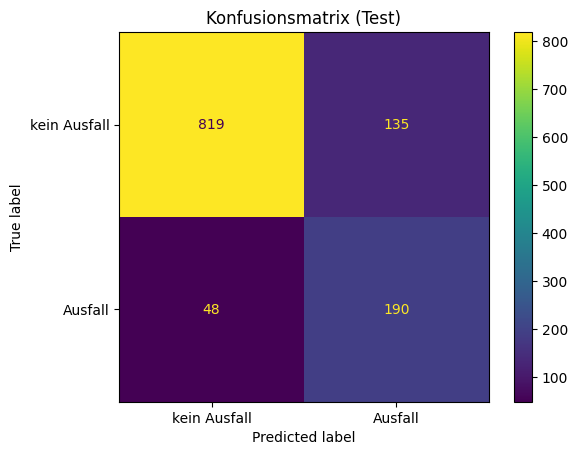

In [ ]:
def evaluate(model, X, y, name):
    pred = model.predict(X)
    proba = model.predict_proba(X)[:, 1]
    return {"Datensatz": name, "F1": f1_score(y, pred), "ROC-AUC": roc_auc_score(y, proba),
            "Accuracy": accuracy_score(y, pred)}

results = pd.DataFrame([evaluate(model, X_train, y_train, "Train"),
                        evaluate(model, X_test, y_test, "Test")]).set_index("Datensatz")
display(results)

pred_test = model.predict(X_test)
print(classification_report(y_test, pred_test, target_names=["kein Ausfall", "Ausfall"]))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=["kein Ausfall", "Ausfall"])
plt.title("Konfusionsmatrix (Test)")
plt.show()

**Interpretation:**
- Der Train-F1 beträgt 0,684 und der Test-F1 0,675. Der Abstand von 0,009 ist klein, daher gibt es keinen Hinweis auf Overfitting. Auch ROC-AUC (0,906 vs. 0,891) und Accuracy (0,852 vs. 0,846) liegen eng beieinander, und der F1-Wert aus der Cross-Validation (0,681) passt dazu.
- Das Modell erkennt 80 % der Ausfälle (Recall 0,80). Von allen Krediten, die es als Ausfall einstuft, fällt nur ein Teil tatsächlich aus (Precision 0,58), der Rest sind Fehlalarme. Das ist eine Folge von `class_weight="balanced"`: Das Modell nimmt mehr Fehlalarme in Kauf, um weniger Ausfälle zu übersehen. Für eine Bank, bei der ein übersehener Ausfall teuer ist, ist das nachvollziehbar. In der Praxis müssten die Kosten beider Fehlerarten abgewogen werden.
- Begründung der Metrik: Accuracy ist bei etwa 20 % Ausfällen irreführend, denn ein Modell, das nie "Ausfall" vorhersagt, hätte bereits rund 80 % (954 von 1.192 Testfällen sind keine Ausfälle). Die erreichten 0,846 liegen nur wenig darüber. F1 verbindet Precision und Recall der Ausfallklasse und zeigt die Leistung dort besser.
- Einordnung: Ein F1 von 0,675 zeigt, dass das lineare Modell die Ausfälle nur teilweise trennt. In 3.3 prüfen wir, ob ein Random Forest dort deutlich besser abschneidet.

## 3. Koeffizienten und Parameter

Die Logistische Regression berechnet zunächst einen Wert (Log-Odds): $\text{logit}(p) = b_0 + b_1 x_1 + \dots + b_k x_k$ und daraus mit der Sigmoid-Funktion den Risikowert $p = \frac{1}{1+e^{-\text{logit}}}$.

- **Koeffizient $b_j$:** Wirkung auf die Log-Odds. Positiv = höheres Ausfallrisiko, negativ = niedrigeres.
- **Odds Ratio $e^{b_j}$:** Faktor, um den sich die Odds (Ausfall zu Nicht-Ausfall) ändern. Bei standardisierten Merkmalen gilt das **pro 1 Standardabweichung** Anstieg, bei One-Hot-Merkmalen und Indikatoren beim Wechsel von 0 auf 1.
- **Achtung bei One-Hot-Spalten:** Es gibt keine Referenzkategorie. Einzelne Koeffizienten (z. B. `JOB_Other`) sind deshalb nur im Vergleich zueinander lesbar, etwa `REASON_HomeImp` gegenüber `REASON_DebtCon`.
- **Achtung bei korrelierten Merkmalen** (z. B. `MORTDUE` und `VALUE`): Die Koeffizienten verteilen sich auf beide und sind einzeln schwer zu deuten.

Intercept b0 = -0.918   (C = 31.6)


,Merkmal,Koeffizient,Odds Ratio
0,VALUE_fehlt,4.913,136.009
1,DEBTINC_fehlt,2.656,14.233
2,JOB_fehlend,-1.414,0.243
3,JOB_Sales,1.060,2.887
4,DELINQ,0.828,2.288
5,JOB_Office,-0.825,0.438
6,CLAGE,-0.548,0.578
7,DEBTINC,0.535,1.707
8,DEROG,0.460,1.584
9,JOB_Self,0.451,1.571


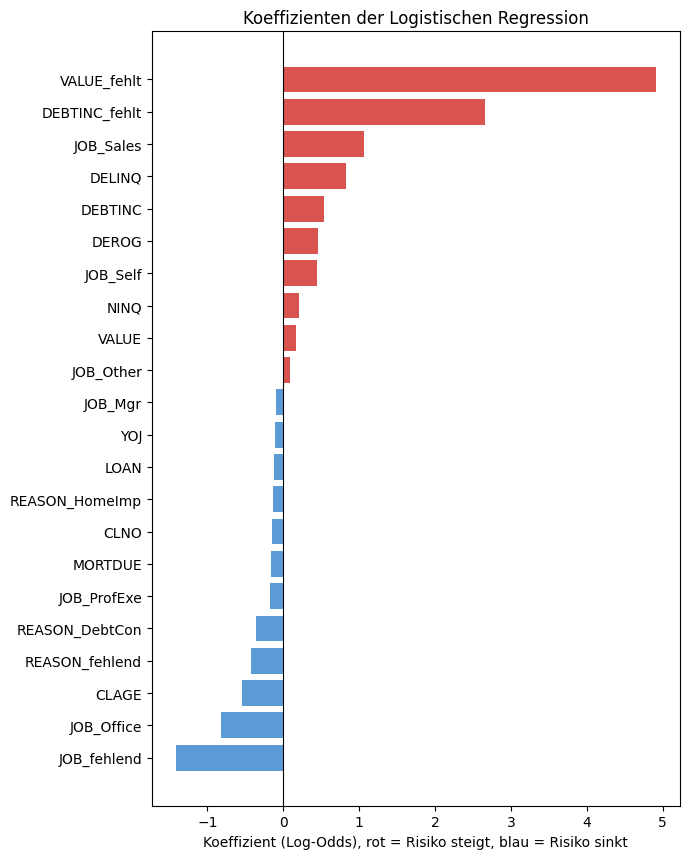

In [ ]:
clf = model.named_steps["clf"]
names = [n.split("__", 1)[1] for n in model.named_steps["prep"].get_feature_names_out()]

coef = pd.DataFrame({"Merkmal": names, "Koeffizient": clf.coef_[0]})
coef["Odds Ratio"] = np.exp(coef["Koeffizient"])
coef = coef.reindex(coef["Koeffizient"].abs().sort_values(ascending=False).index).reset_index(drop=True)

print(f"Intercept b0 = {clf.intercept_[0]:.3f}   (C = {clf.C:.3g})")
display(coef)

plot_df = coef.sort_values("Koeffizient")
plt.figure(figsize=(7, 0.35 * len(plot_df) + 1))
plt.barh(plot_df["Merkmal"], plot_df["Koeffizient"],
         color=np.where(plot_df["Koeffizient"] > 0, "#d9534f", "#5b9bd5"))
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Koeffizient (Log-Odds), rot = Risiko steigt, blau = Risiko sinkt")
plt.title("Koeffizienten der Logistischen Regression")
plt.tight_layout()
plt.show()

**Interpretation:**

*Lesehilfe:* Die numerischen Merkmale sind standardisiert. Der Koeffizient gibt daher die Änderung der Log-Odds pro Standardabweichung an, die Odds Ratio den Faktor für die Odds (Ausfall zu Nicht-Ausfall). Bei Indikatoren und One-Hot-Spalten gilt der Wechsel von 0 auf 1. Der Intercept (−0,918) beschreibt einen gedachten Kredit mit durchschnittlichen Zahlenwerten und allen Kategorie- und Indikatorspalten auf 0. Er ist allein nicht interpretierbar.

*Risikotreiber (Koeffizient > 0):*
- **DELINQ** (0,828; OR 2,29): Mehr überfällige Kreditlinien erhöhen das Risiko deutlich. Pro Standardabweichung (laut EDA etwa 1,1 Kreditlinien) steigen die Odds auf das 2,3-fache.
- **DEBTINC** (0,535; OR 1,71) und **DEROG** (0,460; OR 1,58): höhere Schuldenquote und mehr schwerwiegende negative Einträge erhöhen das Risiko.
- **NINQ** (0,213; OR 1,24): Mehr neue Kreditanfragen wirken leicht risikoerhöhend.
- **JOB_Sales** (1,060; OR 2,89) und **JOB_Self** (0,451; OR 1,57): Vertrieb und Selbstständige haben ein höheres Risiko, was zu den hohen Ausfallraten aus der EDA passt.

*Risikosenker (Koeffizient < 0):*
- **CLAGE** (−0,548; OR 0,58): Eine längere Kredithistorie senkt das Risiko.
- **JOB_Office** (−0,825; OR 0,44): Büroberufe haben ein geringeres Risiko.
- **YOJ** (−0,110), **CLNO** (−0,151) und **LOAN** (−0,124): schwache Effekte. Mehr Jahre im Job und mehr Kreditlinien gehen mit etwas geringerem Risiko einher.

*Fehlende Angaben als Signal:*
- **DEBTINC_fehlt** (2,656; OR 14,2): Fehlt die Schuldenquote, steigen die Odds auf das 14-Fache. Das passt zur EDA (Ausfallrate 62 % bei fehlender gegenüber 8,6 % bei vorhandener Schuldenquote). Dieser Effekt ist der größte unter den Merkmalen mit vielen Beobachtungen.
- **VALUE_fehlt** (4,913; OR 136): Der Wert ist extrem hoch, beruht aber nur auf 89 Trainingszeilen, von denen etwa 93 % ausgefallen sind. Diese Odds Ratio sollte man nicht wörtlich lesen, sie ist eine statistisch instabile Schätzung. Die Aussage "fehlender Immobilienwert bedeutet Ausfall" ist nur für diesen Datensatz belegt.
- **JOB_fehlend** (−1,414; OR 0,24): Fehlt der Beruf, ist das Risiko niedriger. Das passt zur EDA (Ausfallrate von nur 8,2 %). Ein Grund dafür ist nicht erkennbar, die Richtung unterscheidet sich also je nach Merkmal.

*Abgleich mit unseren Erwartungen:*
- Bestätigt: DELINQ, DEROG und DEBTINC erhöhen das Risiko, CLAGE und YOJ senken es, Sales und Self sind riskanter, Office ist weniger riskant. DEROG wirkt allerdings schwächer als DELINQ, obwohl wir beide als stark erwartet hatten.
- Entgegen der Erwartung: **VALUE** hat ein leicht positives Vorzeichen (0,169) und **MORTDUE** ein negatives (−0,161). Wir hatten das Gegenteil erwartet. Beide Merkmale sind mit r ≈ 0,87 stark korreliert, deshalb verteilen sich ihre Effekte auf beide und sind einzeln nicht verlässlich zu deuten.
- Bei REASON liegen alle drei Koeffizienten im Negativen. Da es keine Referenzkategorie gibt, ist nur der Vergleich sinnvoll: `REASON_HomeImp` (−0,132) liegt über `REASON_DebtCon` (−0,358), Renovierungskredite sind also etwas riskanter. Das passt zur EDA (22,3 % gegenüber 19,0 %).

*Wie kommt die Vorhersage zustande?* Das Modell addiert zum Intercept die Beiträge aller Merkmale (Koeffizient mal Merkmalswert) und wandelt die Summe mit der Sigmoid-Funktion in einen Risikowert um. Ab einem Wert von 0,5 sagt es "Ausfall" voraus. Wegen `class_weight="balanced"` ist der Risikowert keine echte Ausfallwahrscheinlichkeit.

## 4. Globale Erklärung (für alle Beobachtungen)

Ein Koeffizient allein sagt noch nicht, wie stark ein Merkmal **im Datensatz** wirkt, denn das hängt auch von seiner Streuung ab. Deshalb betrachten wir zusätzlich den **mittleren absoluten Beitrag** über alle Testbeobachtungen. Der Beitrag eines Merkmals ist `Koeffizient × (Wert − Durchschnittswert in den Trainingsdaten)`, also wie stark ein Kredit bei diesem Merkmal vom **durchschnittlichen Antrag** abweicht. Nur so ist ein Beitrag auch bei One-Hot-Spalten und Indikatoren aussagekräftig. Die Kategorien von `REASON` und `JOB` werden dabei zu je einem Merkmal zusammengefasst.

,Merkmal,mittlerer |Beitrag|
0,DEBTINC_fehlt,0.897
1,DELINQ,0.476
2,CLAGE,0.436
3,DEBTINC,0.372
4,JOB,0.312
5,DEROG,0.225
6,VALUE_fehlt,0.183
7,NINQ,0.146
8,VALUE,0.118
9,MORTDUE,0.114


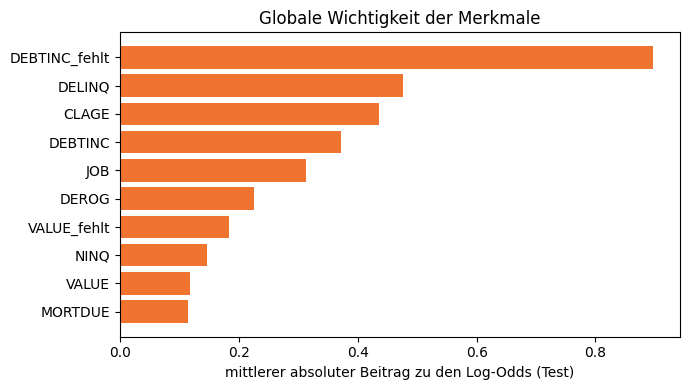

In [ ]:
def transform_dense(model, X):
    Z = model.named_steps["prep"].transform(X)
    return Z.toarray() if hasattr(Z, "toarray") else np.asarray(Z)

Z_train = transform_dense(model, X_train)
Z_test = transform_dense(model, X_test)
# One-Hot-Spalten (REASON_*, JOB_*) werden je ursprünglichem Merkmal zusammengefasst
groups = [n.split("_")[0] if n.startswith(("REASON_", "JOB_")) else n for n in names]
group_names = list(dict.fromkeys(groups))
G = np.zeros((len(names), len(group_names)))
for j, g in enumerate(groups):
    G[j, group_names.index(g)] = 1

z_mean = Z_train.mean(axis=0)                             # durchschnittlicher Antrag (Trainingsdaten)
base_logit = clf.intercept_[0] + (clf.coef_[0] * z_mean).sum()   # Log-Odds des durchschnittlichen Antrags
contrib_test = (Z_test - z_mean) * clf.coef_[0]           # Beitrag je Merkmal und Beobachtung

glob = pd.DataFrame({"Merkmal": group_names,
                     "mittlerer |Beitrag|": np.abs(contrib_test @ G).mean(axis=0)})
glob = glob.sort_values("mittlerer |Beitrag|", ascending=False).reset_index(drop=True)
display(glob.head(10))

top = glob.head(10).iloc[::-1]
plt.figure(figsize=(7, 4))
plt.barh(top["Merkmal"], top["mittlerer |Beitrag|"], color="#f0742f")
plt.xlabel("mittlerer absoluter Beitrag zu den Log-Odds (Test)")
plt.title("Globale Wichtigkeit der Merkmale")
plt.tight_layout()
plt.show()

**Lesehilfe:** Jeder Balken zeigt, wie stark ein Merkmal die Log-Odds eines Kredits gegenüber dem **durchschnittlichen Antrag** erhöht (rot) oder senkt (blau). Der Basiswert plus die Summe der Beiträge ergibt exakt die Log-Odds des Modells (im Code kontrolliert). Die Vorhersage ist also vollständig nachvollziehbar.

**Interpretation der Beispiele:**

- *Richtig erkannter Ausfall (Risikowert 0,78):* Den Ausschlag gibt `DELINQ = 2` (+1,20). Dazu kommen der Beruf `Self` (+0,63) und eine mit 123 Monaten kürzere Kredithistorie als im Durchschnitt (+0,38). Der Abzug von −0,56 bei `DEBTINC` entsteht nur dadurch, dass die Schuldenquote **angegeben** wurde. Das ist ein Effekt der Indikator-Spalte, keine Aussage über den Wert der Schuldenquote.
- *Richtig erkannter Nicht-Ausfall (Risikowert 0,13):* Der Beruf `Office` (−0,65), der hohe Kreditbetrag von 66.400 (−0,53), keine überfälligen Kreditlinien und die angegebene Schuldenquote senken das Risiko deutlich. Dagegen wirken eine Schuldenquote von 40 (+0,43), eine kurze Kredithistorie (+0,41) und der Zweck `HomeImp` (+0,16) erhöhend, reichen aber nicht aus.
- *Übersehener Ausfall (Risikowert 0,21):* Der Kredit hat weder überfällige Kreditlinien noch negative Einträge, und die Schuldenquote ist angegeben. Die beiden Hauptsignale zeigen also keine Warnzeichen. Nur die kurze Kredithistorie (+0,41) und die leicht erhöhte Schuldenquote (36, +0,15) sprechen für ein Risiko. Aus den vorhandenen Merkmalen war dieser Ausfall nicht erkennbar. Das Modell kann nur nutzen, was in den Daten steht, und was zum Ausfall geführt hat, ist darin nicht enthalten.
- *Sonderfall mit fehlendem Immobilienwert (Risikowert 1,00):* Hier fehlen sowohl Immobilienwert (+4,82) als auch Schuldenquote (+2,10). Diese beiden Indikatoren liefern zusammen fast den gesamten Beitrag, die inhaltlichen Merkmale spielen kaum noch eine Rolle. Das Modell stützt sich hier fast nur auf ein Fehlend-Muster der Trainingsdaten. Ob dieses Muster im echten Einsatz weiterhin gilt, ist unklar.

## 5. Lokale Erklärung (einzelne Beobachtungen)

Für einzelne Kredite zerlegen wir die Entscheidung in die Beiträge der Merkmale: Ausgehend vom **durchschnittlichen Antrag** (Basiswert) erhöht oder senkt jedes Merkmal die Log-Odds. Wir wählen vier Beispiele aus dem Testsatz: einen **richtig erkannten Ausfall** (ohne fehlende Angaben), einen **richtig erkannten Nicht-Ausfall**, einen **übersehenen Ausfall** (Fehler des Modells) und einen **Sonderfall mit fehlendem Immobilienwert**, an dem sich der Einfluss der Indikator-Spalte zeigt. Jeweils wird der Fall mit mittlerem Risikowert seiner Gruppe gewählt, nicht ein Extremfall.

--- Richtig erkannter Ausfall (Testzeile 798) ---


,Wert
LOAN,15600
MORTDUE,"62,582.000"
VALUE,"131,510.000"
REASON,DebtCon
JOB,Self
YOJ,2.000
DEROG,0.000
DELINQ,2.000
CLAGE,122.604
NINQ,1.000


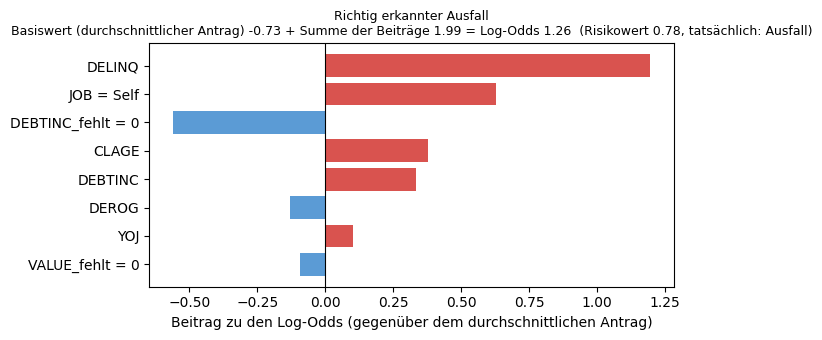

--- Richtig erkannter Nicht-Ausfall (Testzeile 218) ---


,Wert
LOAN,66400
MORTDUE,"69,588.000"
VALUE,"143,926.000"
REASON,HomeImp
JOB,Office
YOJ,12.000
DEROG,0.000
DELINQ,0.000
CLAGE,118.254
NINQ,0.000


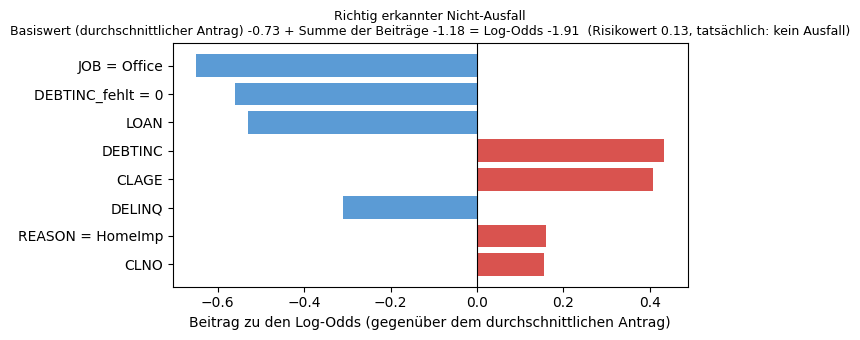

--- Übersehener Ausfall (Testzeile 911) ---


,Wert
LOAN,12600
MORTDUE,"72,854.000"
VALUE,"86,209.000"
REASON,NaN
JOB,ProfExe
YOJ,2.000
DEROG,0.000
DELINQ,0.000
CLAGE,118.070
NINQ,0.000


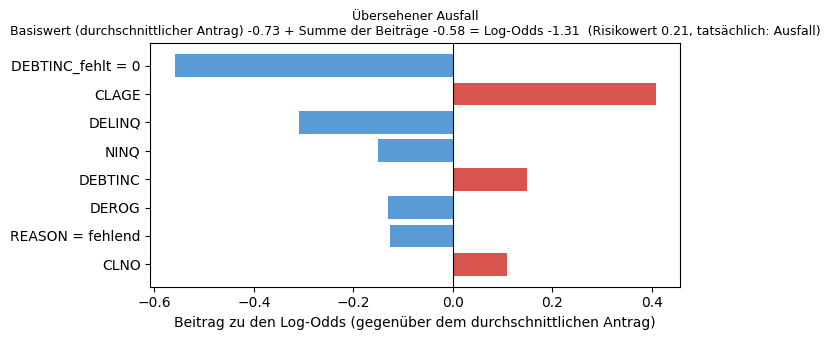

--- Erkannter Ausfall bei fehlendem Immobilienwert (Testzeile 532) ---


,Wert
LOAN,5000
MORTDUE,"81,748.000"
VALUE,NaN
REASON,DebtCon
JOB,ProfExe
YOJ,14.000
DEROG,1.000
DELINQ,2.000
CLAGE,144.067
NINQ,2.000


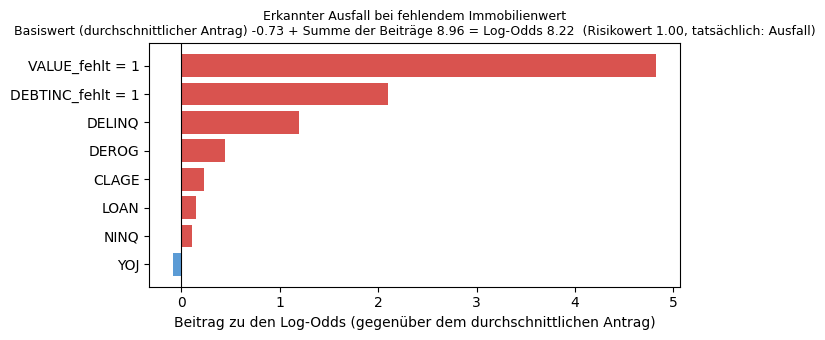

In [ ]:
proba_test = model.predict_proba(X_test)[:, 1]
y_arr = y_test.to_numpy()

def pick_median_case(mask):
    idx = np.where(mask)[0]
    order = idx[np.argsort(proba_test[idx])]
    return int(order[len(order) // 2])

has_ind = X_test[ind_cols].to_numpy().sum(axis=1) > 0          # Zeilen, bei denen DEBTINC oder VALUE fehlt
cases = {
    "Richtig erkannter Ausfall": pick_median_case((y_arr == 1) & (pred_test == 1) & ~has_ind),
    "Richtig erkannter Nicht-Ausfall": pick_median_case((y_arr == 0) & (pred_test == 0)),
    "Übersehener Ausfall": pick_median_case((y_arr == 1) & (pred_test == 0)),
    "Erkannter Ausfall bei fehlendem Immobilienwert": pick_median_case((y_arr == 1) & (pred_test == 1) & (X_test["VALUE_fehlt"].to_numpy() == 1)),
}

def feature_text(g, raw):
    # Beschriftung: Merkmalsname, bei REASON/JOB mit der tatsächlichen Kategorie
    if g in ("REASON", "JOB"):
        return f"{g} = {raw[g] if pd.notna(raw[g]) else 'fehlend'}"
    if g.endswith("_fehlt"):
        return f"{g} = {int(raw[g])}"
    return g

def explain_local(i, top=8, title=""):
    contrib = (Z_test[i] - z_mean) * clf.coef_[0]
    logit = base_logit + contrib.sum()
    assert np.isclose(logit, model.decision_function(X_test.iloc[[i]])[0])   # Kontrolle
    gc = contrib @ G                                          # Beitrag je ursprünglichem Merkmal
    raw = X_test.iloc[i]
    order = np.argsort(np.abs(gc))[::-1][:top][::-1]
    plt.figure(figsize=(7, 3.5))
    plt.barh([feature_text(group_names[j], raw) for j in order], gc[order],
             color=np.where(gc[order] > 0, "#d9534f", "#5b9bd5"))
    plt.axvline(0, color="black", lw=0.8)
    plt.title(f"{title}\nBasiswert (durchschnittlicher Antrag) {base_logit:.2f} + Summe der Beiträge {contrib.sum():.2f} = Log-Odds {logit:.2f}"
              f"  (Risikowert {1/(1+np.exp(-logit)):.2f}, tatsächlich: {'Ausfall' if y_arr[i] else 'kein Ausfall'})",
              fontsize=9)
    plt.xlabel("Beitrag zu den Log-Odds (gegenüber dem durchschnittlichen Antrag)")
    plt.tight_layout()
    plt.show()

for title, i in cases.items():
    print(f"--- {title} (Testzeile {i}) ---")
    display(X_test.iloc[[i]].drop(columns=ind_cols).T.rename(columns={X_test.index[i]: "Wert"}))
    explain_local(i, title=title)

**Interpretation der Beispiele:**

Jeder Balken zeigt, wie stark ein Merkmal die Log-Odds eines Kredits gegenüber dem **durchschnittlichen Antrag** erhöht (rot) oder senkt (blau). Basiswert plus Summe der Beiträge ergibt exakt die Log-Odds des Modells (im Code kontrolliert).

- *Richtig erkannter Ausfall (Risikowert 0,78):* Den Ausschlag gibt `DELINQ = 2` (+1,20). Dazu kommen der Beruf `Self` (+0,63) und die mit 123 Monaten kürzere Kredithistorie als im Durchschnitt (+0,38). Gebremst wird das Ergebnis dadurch, dass die Schuldenquote angegeben wurde (−0,56). Das ist ein Effekt der Indikator-Spalte und keine Aussage über die Höhe der Schuldenquote.
- *Richtig erkannter Nicht-Ausfall (Risikowert 0,13):* Der Beruf `Office` (−0,65), die angegebene Schuldenquote (−0,56) und der hohe Kreditbetrag von 66.400 (−0,53) senken das Risiko deutlich, ebenso die fehlenden Zahlungsverzüge. Dagegen wirken die Schuldenquote von 40 (+0,43), die kurze Kredithistorie (+0,41) und der Zweck `HomeImp` (+0,16) erhöhend, reichen aber nicht aus, um den Schwellenwert zu erreichen.
- *Übersehener Ausfall (Risikowert 0,21):* Der Kredit hat weder überfällige Kreditlinien noch negative Einträge, und die Schuldenquote ist angegeben (−0,56). Die wichtigsten Warnsignale des Modells fehlen also. Nur die kurze Kredithistorie (+0,41) und eine leicht erhöhte Schuldenquote von 36 (+0,15) sprechen für ein Risiko. Das Modell sieht einen unauffälligen Kredit und übersieht, dass er trotzdem ausfällt. Aus den vorhandenen Merkmalen war dieser Ausfall nicht erkennbar. Das zeigt eine Grenze des linearen Modells (z. B. keine Wechselwirkungen, keine nichtlinearen Effekte) und der Daten.
- *Sonderfall fehlender Immobilienwert (Risikowert 1,00):* Hier fehlen sowohl Immobilienwert (+4,82) als auch Schuldenquote (+2,10). Die beiden Indikator-Spalten liefern zusammen rund +6,9 und damit den weitaus größten Teil der Entscheidung. Auch `DELINQ = 2` (+1,20) trägt bei, aber deutlich weniger. Das heißt: Das Modell stützt sich hier vor allem auf ein Fehlend-Muster der Trainingsdaten. Ob dieses Muster im echten Einsatz gilt, ist unklar.

## 6. F.A.S.T.-Check: fair, verlässlich, sicher vor Manipulation, transparent

Die folgenden Prüfungen sind **Stichproben-Analysen** und kein vollständiger Nachweis. Bitte jeweils Befund und Einschätzung ergänzen.

### Fair
Der Datensatz enthält keine geschützten Merkmale wie Alter, Geschlecht oder Herkunft. Wir prüfen deshalb die vorhandenen Gruppen (`JOB`, `REASON`): Werden Gruppen unterschiedlich häufig als riskant eingestuft, und erkennt das Modell Ausfälle in allen Gruppen gleich gut? Kleine Gruppen (z. B. `Sales`, `Self`) liefern im Testsatz nur wenige Fälle, die Werte sind dort unsicher.

In [ ]:
test_eval = X_test.copy()
test_eval["y"] = y_test.to_numpy()
test_eval["pred"] = pred_test

def group_table(col):
    rows = []
    g = test_eval[col].fillna("fehlend")
    for val in sorted(g.unique()):
        d = test_eval[g == val]
        pos = d[d["y"] == 1]
        rows.append({col: val, "n": len(d),
                     "Ausfallrate (tatsächlich)": d["y"].mean(),
                     "Anteil als riskant eingestuft": d["pred"].mean(),
                     "Recall (Ausfälle erkannt)": pos["pred"].mean() if len(pos) else np.nan,
                     "n Ausfälle": len(pos)})
    return pd.DataFrame(rows).set_index(col)

display(group_table("JOB"))
display(group_table("REASON"))

,n,Ausfallrate (tatsächlich),Anteil als riskant eingestuft,Recall (Ausfälle erkannt),n Ausfälle
JOB,,,,,
Mgr,161,0.248,0.323,0.900,40
Office,201,0.159,0.204,0.688,32
Other,451,0.213,0.333,0.833,96
ProfExe,270,0.167,0.196,0.711,45
Sales,17,0.294,0.412,0.600,5
Self,43,0.326,0.372,0.929,14
fehlend,49,0.122,0.122,0.667,6


,n,Ausfallrate (tatsächlich),Anteil als riskant eingestuft,Recall (Ausfälle erkannt),n Ausfälle
REASON,,,,,
DebtCon,800,0.189,0.259,0.775,151
HomeImp,335,0.221,0.316,0.865,74
fehlend,57,0.228,0.211,0.692,13


**Befund Fairness:** Der Datensatz enthält keine geschützten Merkmale, geprüft werden können nur `JOB` und `REASON`. Das Modell stuft in fast allen Gruppen **mehr Kredite als riskant ein, als tatsächlich ausfallen**, was eine Folge von `class_weight="balanced"` ist. Entscheidend ist deshalb das Verhältnis aus eingestuftem Anteil und tatsächlicher Ausfallrate:
- **Beruf:** Bei `Other` werden 33 % als riskant eingestuft bei 21 % tatsächlichen Ausfällen (Faktor 1,6), bei `ProfExe` sind es 20 % bei 17 % (Faktor 1,2). Die Gruppe `Other` wird also überproportional oft als riskant eingestuft. Auch die Trefferquote unterscheidet sich: In `Office` (Recall 0,69) und `ProfExe` (0,71) werden Ausfälle häufiger übersehen als in `Mgr` (0,90), `Other` (0,83) und `Self` (0,93). Wegen der geringen Fallzahlen (zum Beispiel 32 Ausfälle in `Office`, 40 in `Mgr`) lässt sich nicht sicher sagen, ob der Unterschied über Zufall hinausgeht.
- **Kreditzweck:** `HomeImp` wird häufiger als riskant eingestuft als `DebtCon` (31,6 % vs. 25,9 %), das passt zur höheren tatsächlichen Ausfallrate (22,1 % vs. 18,9 %). Das Verhältnis ist mit 1,43 und 1,37 ähnlich, es gibt also keine auffällige Ungleichbehandlung. Der Recall ist bei `HomeImp` mit 0,87 höher als bei `DebtCon` mit 0,78.
- **Kleine Gruppen:** `Sales` (17 Testfälle, 5 Ausfälle), `Self` (43 Fälle, 14 Ausfälle) und die Gruppen mit fehlender Angabe sind zu klein für verlässliche Aussagen.

Einschränkung: `JOB` könnte als Stellvertreter für nicht erfasste Merkmale wirken (zum Beispiel Einkommen), das lässt sich mit diesen Daten nicht prüfen.

F1 in 5-fold CV: Mittel 0.681, Std 0.012, Min 0.665, Max 0.700


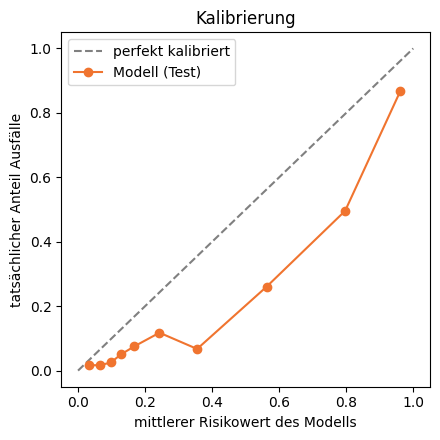

In [ ]:
cv_f1 = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1")
print(f"F1 in 5-fold CV: Mittel {cv_f1.mean():.3f}, Std {cv_f1.std():.3f}, Min {cv_f1.min():.3f}, Max {cv_f1.max():.3f}")

frac_pos, mean_pred = calibration_curve(y_test, proba_test, n_bins=10, strategy="quantile")
plt.figure(figsize=(4.5, 4.5))
plt.plot([0, 1], [0, 1], "--", color="grey", label="perfekt kalibriert")
plt.plot(mean_pred, frac_pos, "o-", color="#f0742f", label="Modell (Test)")
plt.xlabel("mittlerer Risikowert des Modells")
plt.ylabel("tatsächlicher Anteil Ausfälle")
plt.title("Kalibrierung")
plt.legend()
plt.tight_layout()
plt.show()

**Wie stark hängt die Leistung von den Fehlend-Indikatoren ab?** Wir trainieren das Modell mit demselben `C` ohne einzelne oder beide Indikatoren neu und vergleichen die Testleistung.

In [ ]:
def fit_variant(ind_keep):
    prep_v = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
        ("ind", "passthrough", ind_keep),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="fehlend")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
    ])
    p = Pipeline([("prep", prep_v),
                  ("clf", LogisticRegression(class_weight="balanced", max_iter=5000, C=clf.C))])
    p.fit(X_train, y_train)
    return {"F1 (Test)": f1_score(y_test, p.predict(X_test)),
            "ROC-AUC (Test)": roc_auc_score(y_test, p.predict_proba(X_test)[:, 1])}

variants = {
    "mit beiden Indikatoren (unser Modell)": ind_cols,
    "ohne VALUE_fehlt": ["DEBTINC_fehlt"],
    "ohne DEBTINC_fehlt": ["VALUE_fehlt"],
    "ohne beide Indikatoren": [],
}
display(pd.DataFrame({k: fit_variant(v) for k, v in variants.items()}).T)

,F1 (Test),ROC-AUC (Test)
mit beiden Indikatoren (unser Modell),0.675,0.891
ohne VALUE_fehlt,0.667,0.880
ohne DEBTINC_fehlt,0.513,0.784
ohne beide Indikatoren,0.500,0.768


**Befund Verlässlichkeit:** Die Leistung ist über die Daten-Teilmengen **stabil**: In der 5-fold Cross-Validation liegt F1 im Mittel bei 0,681 mit einer Standardabweichung von 0,012 (Minimum 0,665, Maximum 0,700). Zwei Einschränkungen:
1. **Starke Abhängigkeit von einem Fehlend-Muster.** Ohne `DEBTINC_fehlt` sinkt die Test-AUC von 0,891 auf 0,784 (F1 von 0,675 auf 0,513), ohne `VALUE_fehlt` nur auf 0,880. Ohne beide Indikatoren liegt sie bei 0,768. Das Modell stützt sich also vor allem darauf, ob die Schuldenquote angegeben wurde. Ob dieses Muster im echten Einsatz gilt, ist unsicher.
2. **Der Risikowert ist nicht kalibriert.** Die Kalibrierungskurve liegt deutlich unter der Diagonale (bei Risikowerten um 0,8 fällt nur etwa die Hälfte der Kredite aus). Das ist eine Folge von `class_weight="balanced"`. Der Wert eignet sich für eine Rangfolge, nicht als Ausfallwahrscheinlichkeit.

In [ ]:
def what_if(i, **changes):
    row = X_test.iloc[[i]].copy()
    for k, v in changes.items():
        row[k] = v
    row["DEBTINC_fehlt"] = int(row["DEBTINC"].isna().iloc[0])
    row["VALUE_fehlt"] = int(row["VALUE"].isna().iloc[0])
    return float(model.predict_proba(row)[0, 1])

# Fall für den Test: erkannter Ausfall mit angegebener Schuldenquote und Zahlungsverzug (sonst wären manche Szenarien wirkungslos)
mask = (y_arr == 1) & (pred_test == 1) & X_test["DEBTINC"].notna().to_numpy() & (X_test["DELINQ"].fillna(0) > 0).to_numpy()
if not mask.any():
    mask = (y_arr == 1) & (pred_test == 1) & X_test["DEBTINC"].notna().to_numpy()
i = pick_median_case(mask)
print("Betrachteter Antrag (Testzeile", i, "):")
display(X_test.iloc[[i]][["DEBTINC", "YOJ", "JOB", "REASON", "DELINQ"]])

median_debtinc = X_train["DEBTINC"].median()
median_yoj = X_train["YOJ"].median()
scenarios = {
    "Originalantrag": {},
    "Schuldenquote auf Median gesetzt": {"DEBTINC": median_debtinc},
    "Schuldenquote nicht angegeben": {"DEBTINC": np.nan},
    "Jahre im Job auf Median gesetzt": {"YOJ": median_yoj},
    "Beruf = Office": {"JOB": "Office"},
    "Zweck = DebtCon": {"REASON": "DebtCon"},
    "alle vier Angaben beschönigt": {"DEBTINC": median_debtinc, "YOJ": median_yoj, "JOB": "Office", "REASON": "DebtCon"},
    "DELINQ auf 0 gesetzt (Auskunftei-Merkmal)": {"DELINQ": 0},
}
manip = pd.DataFrame({"Risikowert": {k: what_if(i, **v) for k, v in scenarios.items()}})
manip["Änderung"] = manip["Risikowert"] - manip.loc["Originalantrag", "Risikowert"]
display(manip)

Betrachteter Antrag (Testzeile 1164 ):


,DEBTINC,YOJ,JOB,REASON,DELINQ
1504,40.761,NaN,Other,HomeImp,1.000


,Risikowert,Änderung
Originalantrag,0.791,0.000
Schuldenquote auf Median gesetzt,0.711,-0.080
Schuldenquote nicht angegeben,0.972,0.181
Jahre im Job auf Median gesetzt,0.791,0.000
Beruf = Office,0.602,-0.189
Zweck = DebtCon,0.751,-0.040
alle vier Angaben beschönigt,0.439,-0.351
DELINQ auf 0 gesetzt (Auskunftei-Merkmal),0.640,-0.150


**Befund Manipulation:** Am Beispielantrag (Testzeile 1164, Risikowert 0,79, als riskant eingestuft) zeigt sich, dass beschönigte Angaben das Ergebnis deutlich verschieben:
- Setzt der Antragsteller die Schuldenquote auf den Median, sinkt der Risikowert auf 0,71. Der Beruf `Office` statt `Other` senkt ihn auf 0,60, der Zweck `DebtCon` auf 0,75.
- Werden Schuldenquote, Beruf und Zweck zusammen beschönigt, fällt er auf **0,44 und die Entscheidung kippt unter die Schwelle von 0,5**. (Das Setzen der Jahre im Job bewirkt nichts, weil dieser Wert im Antrag fehlte und ohnehin mit dem Median ersetzt wird.)
- Wer die Schuldenquote **nicht angibt**, wird dagegen schlechter eingestuft (0,97). Das Weglassen lohnt sich also nicht.
- Auch das Auskunftei-Merkmal `DELINQ` verändert den Wert, wenn es auf 0 gesetzt wird (0,64), wäre aber schwerer zu manipulieren.

Besonders angreifbar sind selbst angegebene Merkmale (Beruf, Schuldenquote, Zweck). Das ist ein Einzelfall und keine allgemeine Aussage, und ob die Angaben tatsächlich prüfbar sind, wissen wir nicht (Annahme). Mögliche Gegenmaßnahmen: Angaben mit Belegen prüfen, Plausibilitätskontrollen und nur verifizierte Merkmale nutzen.

### Transparent
- Das Modell ist **intrinsisch erklärbar**: Jede Vorhersage ist eine Summe aus Merkmalsbeiträgen, die wir exakt nachrechnen konnten (Kontrolle im Code). Es braucht keine Näherungsverfahren.
- Die Vorverarbeitung ist vollständig dokumentiert (Pipeline und Regeln aus der EDA).
- **Transparent heißt nicht verlässlich:** Die Koeffizienten sind vollständig einsehbar, aber nicht alle sind belastbar. `VALUE_fehlt` hat eine Odds Ratio von 136, beruht aber nur auf 89 Trainingszeilen. Das Modell legt also offen, dass es sich auf ein Fehlend-Muster stützt, rechtfertigt das aber nicht.
- Für Laien sind standardisierte Koeffizienten und Log-Odds schwer verständlich. Transparenz gegenüber Sachbearbeitern oder Antragstellern braucht deshalb eine Übersetzung in verständliche Gründe (siehe Abschnitt 7).
- Grenzen: Die Koeffizienten beschreiben **Zusammenhänge, keine Ursachen**. Korrelierte Merkmale (`VALUE`/`MORTDUE`) erschweren die Einzeldeutung, das lineare Modell kann keine Wechselwirkungen abbilden, und die Herkunft der Daten ist unklar.

**Gesamteinschätzung F.A.S.T.:**
- **Fair:** teilweise. Wir können nur eingeschränkt prüfen (keine geschützten Merkmale, kleine Gruppen), sehen aber, dass `Other` überproportional oft als riskant eingestuft wird und die Trefferquote zwischen Berufsgruppen schwankt.
- **Verlässlich:** eingeschränkt. Stabil über die Cross-Validation, aber stark abhängig von einem Fehlend-Muster und nicht kalibriert.
- **Sicher vor Manipulation:** schwach bei selbst angegebenen Merkmalen. Mehrere beschönigte Angaben können die Entscheidung kippen.
- **Transparent:** ja. Das Modell ist intrinsisch erklärbar und jede Vorhersage nachrechenbar, auch wenn nicht alle Koeffizienten belastbar sind.

## 7. Explainable Interface

Wie könnte ein Interface aussehen, das die Entscheidung für **Sachbearbeiter** (und ggf. für Antragsteller) verständlich macht? Vorschlag einer "Entscheidungskarte" mit diesen Elementen (bitte mit der Vorlesung 1 abgleichen):
1. **Ergebnis** (Prüfempfehlung) und Risikowert, mit Hinweis auf die Unsicherheit.
2. **Hauptgründe**, die das Risiko erhöhen bzw. senken, in Alltagssprache.
3. **Was-wäre-wenn-Hinweis**, welche Angaben das Ergebnis am stärksten beeinflussen.
4. **Hinweis auf menschliche Entscheidung**: Das Modell unterstützt, es entscheidet nicht allein.

Unten ein Textprototyp.

In [ ]:
LABELS = {
    "LOAN": "Kreditbetrag", "MORTDUE": "Offene Hypothek", "VALUE": "Immobilienwert", "YOJ": "Jahre im Job",
    "DEROG": "Schwerwiegende negative Einträge", "DELINQ": "Überfällige Kreditlinien", "CLAGE": "Alter der ältesten Kreditlinie",
    "NINQ": "Neue Kreditanfragen", "CLNO": "Anzahl Kreditlinien", "DEBTINC": "Schuldenquote",
    "REASON": "Kreditzweck", "JOB": "Beruf",
    "DEBTINC_fehlt": "Schuldenquote nicht angegeben", "VALUE_fehlt": "Immobilienwert nicht angegeben",
}
def label(n):
    return LABELS.get(n, n)

def decision_card(i, top=3):
    contrib = ((Z_test[i] - z_mean) * clf.coef_[0]) @ G       # Beitrag je ursprünglichem Merkmal
    p = proba_test[i]
    raw = X_test.iloc[i]
    up = [j for j in np.argsort(contrib)[::-1] if contrib[j] > 0][:top]
    down = [j for j in np.argsort(contrib) if contrib[j] < 0][:top]

    def value_text(n):
        if n in ("REASON", "JOB"):
            return f" = {raw[n] if pd.notna(raw[n]) else 'fehlend'}"
        if n.endswith("_fehlt") or n not in raw.index or pd.isna(raw[n]):
            return ""
        v = raw[n]
        if isinstance(v, (int, float, np.number)):
            return f" = {v:,.0f}" if float(v).is_integer() else f" = {v:,.1f}"
        return f" = {v}"

    def full_text(g):
        if g.endswith("_fehlt"):
            base = g[:-6]
            return f"{LABELS[base]} {'nicht angegeben' if pd.isna(raw[base]) else 'angegeben'}"
        return label(g) + value_text(g)

    print("=" * 62)
    print(f" ANTRAG (Testzeile {i})")
    print("=" * 62)
    print(" Empfehlung :", "HOHES RISIKO - manuelle Prüfung empfohlen" if pred_test[i] == 1 else "geringes Risiko laut Modell")
    print(f" Risikowert : {p:.2f}  (Schwelle 0.50, nicht kalibriert)")
    print("-" * 62)
    print(" Erhöht das Risiko (gegenüber einem durchschnittlichen Antrag):")
    for j in up:   print(f"   + {full_text(group_names[j])}  ({contrib[j]:+.2f})")
    print(" Senkt das Risiko (gegenüber einem durchschnittlichen Antrag):")
    for j in down: print(f"   - {full_text(group_names[j])}  ({contrib[j]:+.2f})")
    print("-" * 62)
    print(" Hinweis: Modellschätzung als Entscheidungshilfe. Die Entscheidung")
    print(" trifft ein Mensch. Widerspruch und Erklärung sind möglich.")
    print("=" * 62)

for title, i in cases.items():
    print(f"\n>>> {title}")
    decision_card(i)


>>> Richtig erkannter Ausfall
 ANTRAG (Testzeile 798)
 Empfehlung : HOHES RISIKO - manuelle Prüfung empfohlen
 Risikowert : 0.78  (Schwelle 0.50, nicht kalibriert)
--------------------------------------------------------------
 Erhöht das Risiko (gegenüber einem durchschnittlichen Antrag):
   + Überfällige Kreditlinien = 2  (+1.20)
   + Beruf = Self  (+0.63)
   + Alter der ältesten Kreditlinie = 122.6  (+0.38)
 Senkt das Risiko (gegenüber einem durchschnittlichen Antrag):
   - Schuldenquote angegeben  (-0.56)
   - Schwerwiegende negative Einträge = 0  (-0.13)
   - Immobilienwert angegeben  (-0.09)
--------------------------------------------------------------
 Hinweis: Modellschätzung als Entscheidungshilfe. Die Entscheidung
 trifft ein Mensch. Widerspruch und Erklärung sind möglich.

>>> Richtig erkannter Nicht-Ausfall
 ANTRAG (Testzeile 218)
 Empfehlung : geringes Risiko laut Modell
 Risikowert : 0.13  (Schwelle 0.50, nicht kalibriert)
-----------------------------------------------

**Einordnung:** Der Prototyp setzt drei der vier geplanten Elemente um: die Prüfempfehlung mit Risikowert, die Hauptgründe in Alltagssprache (gegenüber dem durchschnittlichen Antrag) und den Hinweis auf die menschliche Entscheidung. Der **Was-wäre-wenn-Hinweis** fehlt noch. Eine Grundlage dafür liefert der Manipulationstest aus Abschnitt 6. Ebenfalls nicht umgesetzt ist eine Angabe zur Unsicherheit, der Hinweis "nicht kalibriert" ersetzt sie nur zum Teil.

**Was die Beispielkarten zeigen:**
- *Die Karten legen Schwächen des Modells offen.* In der Karte zum fehlenden Immobilienwert (Risikowert 1,00) stammen die beiden größten Beiträge (+4,82 und +2,10) von Fehlend-Indikatoren und nicht von Eigenschaften des Kreditnehmers. In den anderen Karten erscheint "Schuldenquote angegeben" als wichtiger risikosenkender Faktor (−0,56). Für Laien klingt das unplausibel oder ungerecht, für einen Sachbearbeiter ist es ein wichtiger Hinweis, dass das Modell hier ein Datenmuster nutzt. Eine Warnung wie "Die Entscheidung beruht überwiegend auf fehlenden Angaben" wäre sinnvoll.
- *Log-Odds sind für Laien ungeeignet.* Werte wie "+1,20" lassen sich ohne Fachwissen nicht einordnen. Besser wären Balken oder Abstufungen ("stark erhöhend", "leicht senkend").
- *Der Risikowert ist keine Wahrscheinlichkeit.* Eine reale Oberfläche sollte Kategorien (niedrig, mittel, hoch) statt "0,78" zeigen, um falsche Genauigkeit zu vermeiden.

**Für wen soll die Erklärung sein?**
- *Sachbearbeiter* brauchen die Gründe, den Hinweis auf Modellgrenzen und die Möglichkeit, das Ergebnis zu übersteuern.
- *Antragsteller* brauchen eine verständliche Begründung und einen Weg zum Widerspruch.
- *Prüfer und Aufsicht* brauchen die Modelldokumentation und die Gesamtauswertung.

**Zielkonflikt Transparenz und Manipulation:** Ein Was-wäre-wenn-Hinweis ("mit anderem Beruf wäre der Kredit genehmigt worden") hilft Antragstellern, kann aber zum Beschönigen von Angaben einladen. Das knüpft an die Befunde zu "Transparent" und "Sicher vor Manipulation" an. Die Erklärung sollte sich deshalb auf prüfbare Merkmale beschränken.

**Bezug zum EU AI Act (bitte im Gesetzestext prüfen):** Für Hochrisiko-Systeme verlangt Art. 13 eine ausreichende Transparenz, damit Betreiber die Ausgaben richtig interpretieren und nutzen können. Art. 14 verlangt eine wirksame menschliche Aufsicht. Dazu gehört, die Grenzen des Systems zu kennen, der Gefahr zu begegnen, sich zu stark auf die Ausgabe zu verlassen (Automation Bias), und das Ergebnis übersteuern zu können. Unser Interface adressiert das teilweise (Gründe, Hinweis auf menschliche Entscheidung), für einen echten Einsatz fehlen unter anderem Unsicherheitsangaben, eine Warnung bei fehlenden Daten und die Dokumentation.

**Bezug zur Vorlesung:** … (bitte ergänzen: Welche Bestandteile eines Explainable Interface nennt Vorlesung 1, und welche davon setzt unser Prototyp um?)